## Lab 2

Step 1 - Create Dummy Dataset

In [1]:
import numpy as np
from sklearn.datasets import make_classification

# Create dummy data
# The output of make_classification consists of feature data X and labels y
# The labels y will be encoded (numerical) data
X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

# By default, make_classification produces float values
# We need to convert them to discrete form

# Take the absolute value of the values
X = np.absolute(X)

# Round values to two decimal places
# Multiply by 100 so that there are no decimal points
X = np.round(X, 2) * 100

# Convert to integer type
X = X.astype(int)

# Check the result
print(X)
print(y)

[[202 225]
 [154 176]
 [ 77  57]
 [131 148]
 [183 213]
 [121 123]
 [ 74  55]
 [151 165]
 [146 120]
 [ 26  79]
 [  7  76]
 [ 61  92]
 [ 61  94]
 [ 92  94]
 [ 61  91]
 [ 57  86]
 [100  65]
 [ 86  60]
 [164 209]
 [128 165]
 [160 219]
 [142 194]
 [154 229]
 [ 54  84]
 [374 157]
 [ 76  87]
 [ 81 101]
 [200 129]
 [142 101]
 [ 23  69]]
[0 0 0 0 0 1 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


Step 2 (Optional) - Create DataFrame

In [2]:
import pandas as pd

# Reshape label y into 2D
# This is done because we will concatenate it with the feature data X
y_new = y.reshape(len(y), 1)

# Concatenate features X and label y into an array
data = np.concatenate((X, y_new), axis=1)

# Define column names
nama_kolom = ['Feature 1', 'Feature 2', 'Label']

# Create DataFrame
df = pd.DataFrame(data, columns=nama_kolom)

# Inspect the DataFrame
df.head()

,Feature 1,Feature 2,Label
0,202,225,0
1,154,176,0
2,77,57,0
3,131,148,0
4,183,213,0


Step 3 (Optional) - Labeling

In [3]:
# Define label names
labels = {
    1 : 'Class A',
    0 : 'Class B'
}

# Copy the DataFrame to create a new DataFrame
# with more readable labels
df_label = df.copy()

# Replace labels using the Pandas mapping function
# on the df_label DataFrame
df_label['Label'] = df_label['Label'].map(labels)

# Inspect the df_label DataFrame
df_label.head()

,Feature 1,Feature 2,Label
0,202,225,Class B
1,154,176,Class B
2,77,57,Class B
3,131,148,Class B
4,183,213,Class B


Step 4 - Data Visualization

<ArrowStringArray>
['Class B', 'Class A']
Length: 2, dtype: str


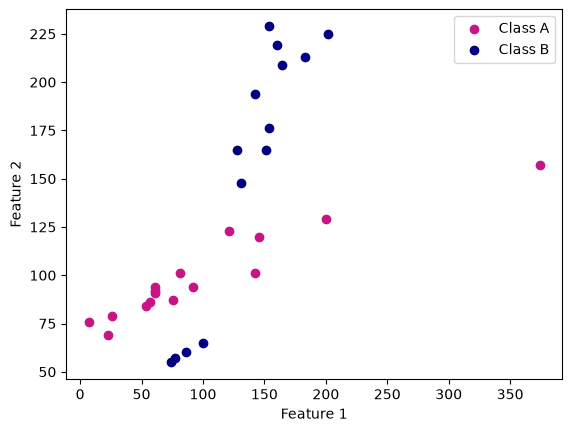

In [7]:
import matplotlib.pyplot as plt

print(df_label['Label'].unique())  # should show Class A and Class B

class_a = df_label[df_label['Label'] == 'Class A']
class_b = df_label[df_label['Label'] == 'Class B']

plt.scatter(class_a['Feature 1'], class_a['Feature 2'],
            c='MediumVioletRed', label='Class A')
plt.scatter(class_b['Feature 1'], class_b['Feature 2'],
            c='Navy', label='Class B')

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.show()

Step 5 - Multinomial Naive Bayes Model

In [9]:
from sklearn.naive_bayes import MultinomialNB # class for the MultinomialNB model
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score # evaluate the model using accuracy

# Instantiate a MultinomialNB object
mnb = MultinomialNB()

# We can directly use the feature matrix X and labels y
# resulting from the dummy data generation process

# Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

# Fit the model
# The label y must be in 1D form or (n_samples,)
mnb.fit(X_train, y_train)

# Predict on training data
y_train_pred = mnb.predict(X_train)

# Evaluate training accuracy
acc_train = accuracy_score(y_train, y_train_pred)

# Predict test data
y_test_pred = mnb.predict(X_test)

# Evaluate the model using the accuracy metric
acc_test = accuracy_score(y_test, y_test_pred)

# Print evaluation results
print(f'Training accuracy: {acc_train}')
print(f'Test accuracy: {acc_test}')

Training accuracy: 0.6666666666666666
Test accuracy: 0.4444444444444444


Step 6 - Gaussian Naive Bayes Model

In [10]:
from sklearn.naive_bayes import GaussianNB # class for the GaussianNB model

# Instantiate a Gaussian object
gnb = GaussianNB()

# We use the same training and testing split
# as used for the multinomial model

# Fit the model
# The label y must be in 1D form or (n_samples,)
gnb.fit(X_train, y_train)

# Predict on training data
y_train_pred_gnb = gnb.predict(X_train)

# Evaluate training accuracy
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Predict test data
y_test_pred_gnb = gnb.predict(X_test)

# Evaluate the model using the accuracy metric
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

# Print evaluation results
print(f'Training accuracy (Gaussian): {acc_train_gnb}')
print(f'Test accuracy (Gaussian): {acc_test_gnb}')

Training accuracy (Gaussian): 0.7619047619047619
Test accuracy (Gaussian): 0.7777777777777778
